# N03: SigLIP, searching the image itself

A different branch: no text about the painting at all. SigLIP was trained on image-caption pairs so that a sentence
and a matching image land close together; we compare the visitor's query (text tower) with each painting (image
tower). R4 is compared with the baseline R1, not with R3 (it changes the encoder, the modality and the text at once).

The image embeddings are computed once and cached; at query time only the query goes through the text tower.

In [1]:

from deep_learning_project_waerniers_lamy_mahieddine.nlp import utils as u

c:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
paintings = u.load_corpus("dev")
descriptions = u.load_descriptions()
queries = u.QUERIES["text"].tolist()
scores = {
    "R0 random": u.rung_random(paintings, queries),
    "R1 metadata": u.rung_metadata(paintings, queries),
    "R2 description": u.rung_description(paintings, queries, descriptions),
    "R3 description+metadata": u.rung_description_metadata(paintings, queries, descriptions),
    "R4 siglip image": u.rung_siglip(paintings, queries),
}
u.judge_with_llm("dev", scores, paintings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2427.52it/s]
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 408/408 [00:00<00:00, 440.60it/s]


123 new (query, painting) pairs to grade with google/gemini-3.8-flash
100/123
767 judgments in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\qrels_dev.json, 0 failed


{'q01': {'s42_r0523': 0,
  's49_r0203': 0,
  's51_r0277': 0,
  's51_r0672': 0,
  's51_r0941': 0,
  's51_r0947': 0,
  's51_r1050': 0,
  's54_r0082': 0,
  's54_r0375': 2,
  's54_r0424': 2,
  's54_r0450': 2,
  's54_r0593': 2,
  's54_r0618': 2,
  's54_r0714': 0,
  's58_r0276': 0,
  's58_r0692': 0,
  's54_r0667': 2,
  's54_r0601': 2},
 'q02': {'s42_r0640': 0,
  's49_r0183': 0,
  's49_r0261': 0,
  's49_r0303': 0,
  's49_r0317': 0,
  's49_r0533': 0,
  's49_r0642': 0,
  's51_r0444': 0,
  's54_r0274': 1,
  's54_r0346': 2,
  's54_r0451': 1,
  's54_r0567': 2,
  's54_r0659': 1,
  's54_r0672': 2,
  's54_r0677': 2,
  's54_r0763': 1,
  's58_r0296': 0,
  's58_r0604': 0,
  's54_r0319': 2},
 'q03': {'s42_r0268': 1,
  's42_r0695': 2,
  's49_r0454': 2,
  's49_r1014': 1,
  's54_r0278': 0,
  's54_r0333': 0,
  's54_r0346': 0,
  's54_r0375': 0,
  's54_r0460': 0,
  's54_r0496': 0,
  's54_r0550': 0,
  's54_r0726': 0,
  's58_r0135': 1,
  's58_r0183': 1,
  's58_r0354': 2,
  's58_r0391': 1,
  's58_r0129': 1},
 'q0

### Judging

Every painting in the new top 5 of a rung is graded by an LLM judge (`u.JUDGE_MODEL`, another model family than the
description generator). It sees **only the query and the image**, answers two yes/no questions (is the main subject
there? does it match the whole query?) and the grade follows by rule: 0, 1 or 2. Grades are saved in
`results/nlp/qrels_dev.json`; already graded pairs are never sent again. The judge is validated against 150 of your own
grades in N04 before any result is frozen.

## Results

Pre-registered comparison 2 of 3: **does a visual embedding beat metadata?** (R4 vs R1).

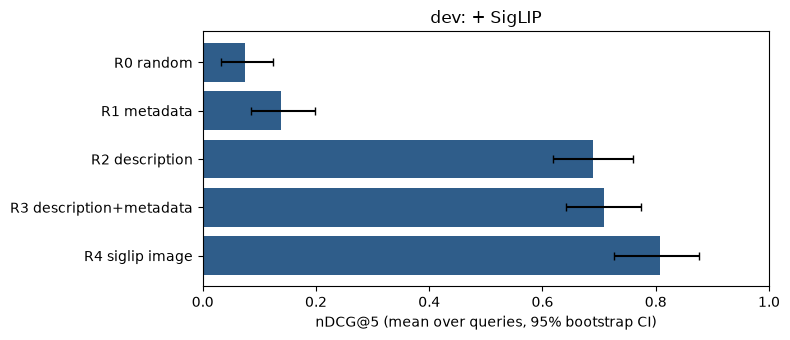

,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,39,0.074,0.033,0.124,0.128,0.026,0.231,1.0
1,R1 metadata,39,0.139,0.086,0.198,0.256,0.128,0.385,1.0
2,R2 description,39,0.689,0.619,0.760,0.923,0.821,1.000,1.0
3,R3 description+metadata,39,0.708,0.641,0.774,0.923,0.821,1.000,1.0
4,R4 siglip image,39,0.808,0.726,0.877,0.897,0.795,0.974,1.0


,system,reference,delta nDCG@5,p,p (Holm)
0,R4 siglip image,R1 metadata,0.6695,0.0001,0.0001


In [3]:
per_query = u.per_query_scores("dev", scores, paintings)
table = u.summary_table(per_query)
u.plot_ladder(table, "dev: + SigLIP")
display(table)
u.compare(per_query, [("R4 siglip image", "R1 metadata")])

In [4]:
per_query.groupby(["rung", "category"])["ndcg@5"].mean().unstack().round(3)

category,compound,mood_colour,object,scene
rung,,,,
R0 random,0.014,0.233,0.042,0.020
R1 metadata,0.146,0.305,0.084,0.043
R2 description,0.592,0.700,0.820,0.624
R3 description+metadata,0.633,0.735,0.802,0.646
R4 siglip image,0.824,0.876,0.747,0.799
